x	Euler	Exact	Absolute error
0.0	0.50000000	0.50000000	0.00000000e+00
0.1	0.65000000	0.65741454	7.41454096e-03
0.2	0.81400000	0.82929862	1.52986209e-02
0.3	0.99140000	1.01507060	2.36705962e-02
0.4	1.18154000	1.21408765	3.25476512e-02
0.5	1.38369400	1.42563936	4.19453646e-02
0.6	1.59706340	1.64894060	5.18771998e-02
0.7	1.82076974	1.88312365	6.23539063e-02
0.8	2.05384671	2.12722954	7.33828218e-02
0.9	2.29523139	2.38019844	8.49670590e-02
1.0	2.54375452	2.64085909	9.71045618e-02


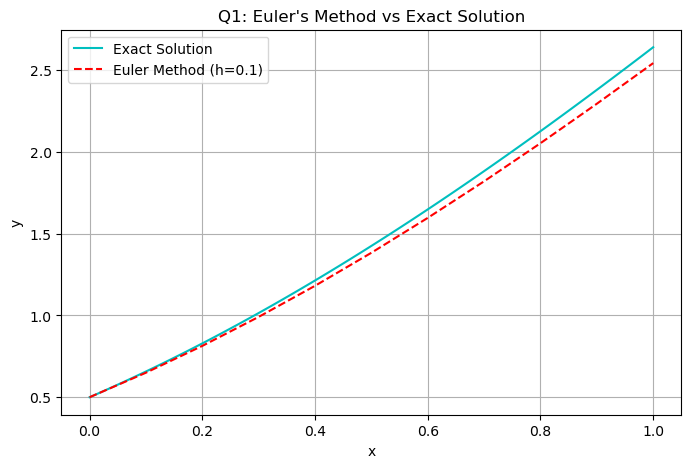

In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

def save_op(n):
    text_path = Path(f"Q{n}.txt")
    text_path.write_text("", encoding="utf-8")
    plt_n = 0

    def print_r(*args, **kwargs):
        print(*args, **kwargs)
        with text_path.open("a", encoding="utf-8") as output:
            print(*args, file=output, **kwargs)

    def show_plt():
        nonlocal plt_n
        plt_n += 1
        path = Path(f"Q{n}_plot_{plt_n:02d}.png")
        plt.savefig(path, bbox_inches="tight")
        plt.show()

    return print_r, show_plt

print_r, show_plt = save_op(1)


def euler_method(f, x0, y0, x_end, h):
    n_steps = int(np.round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n_steps + 1)
    y = np.zeros(n_steps + 1)
    y[0] = y0
    for i in range(n_steps):
        y[i+1] = y[i] + h * f(x[i], y[i])
    return x, y


f = lambda x, y: y - x**2 + 1
exact_f = lambda x: (x + 1)**2 - 0.5 * np.exp(x)
x_num, y_num = euler_method(f, 0, 0.5, 1, 0.1)

exact_nodes = exact_f(x_num)
print_r("x", "Euler", "Exact", "Absolute error", sep="\t")
for x, y, exact, error in zip(x_num, y_num, exact_nodes, np.abs(y_num - exact_nodes)):
    print_r(f"{x:.1f}\t{y:.8f}\t{exact:.8f}\t{error:.8e}")

x_exact = np.linspace(0, 1, 100)
y_exact = exact_f(x_exact)

plt.figure(figsize=(8, 5))
plt.plot(x_exact, y_exact, 'c-', label="Exact Solution")
plt.plot(x_num, y_num, 'r--', label="Euler Method (h=0.1)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q1: Euler's Method vs Exact Solution")
plt.legend()
plt.grid(True)
show_plt()

Backward Euler factor = 0.16666666666666666
Forward Euler factor = -4.0
Maximum absolute error = 0.15992871966758118


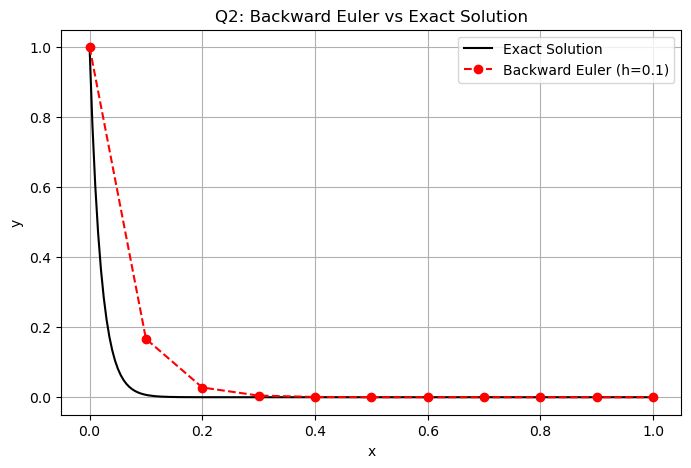

In [ ]:
# Q2

print_r, show_plt = save_op(2)


def backward_euler_q2(x0, y0, x_end, h):
    # Explicit formula specific to Q2: y' = -50y
    n_steps = int(np.round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n_steps + 1)
    y = np.zeros(n_steps + 1)
    y[0] = y0
    for i in range(n_steps):
        y[i+1] = y[i]/(1 + 50 * h)
    return x, y


exact_f = lambda x: np.exp(-50 * x)
x_num, y_num = backward_euler_q2(0, 1, 1, 0.1)

h = 0.1
print_r("Backward Euler factor =", 1/(1 + 50 * h))
print_r("Forward Euler factor =", 1 - 50 * h)
print_r("Maximum absolute error =", np.max(np.abs(y_num - exact_f(x_num))))

x_exact = np.linspace(0, 1, 200)
y_exact = exact_f(x_exact)

plt.figure(figsize=(8, 5))
plt.plot(x_exact, y_exact, 'k-', label="Exact Solution")
plt.plot(x_num, y_num, 'ro--', label="Backward Euler (h=0.1)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q2: Backward Euler vs Exact Solution")
plt.legend()
plt.grid(True)
show_plt()

Forward Euler maximum absolute error = 0.24907873671809
Heun maximum absolute error = 0.00840196370164037


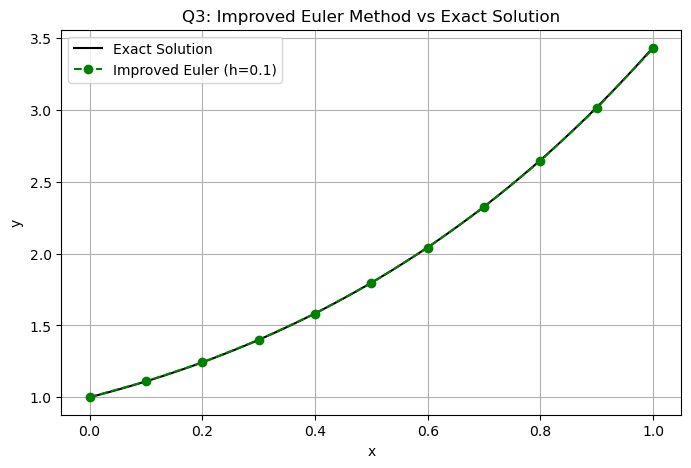

In [ ]:
# Q3

print_r, show_plt = save_op(3)

def improved_euler(f, x0, y0, x_end, h):
    n_steps = int(np.round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n_steps + 1)
    y = np.zeros(n_steps + 1)
    y[0] = y0
    for i in range(n_steps):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h, y[i] + h * k1)
        y[i+1] = y[i] + (h/2) * (k1 + k2)
    return x, y


f = lambda x, y: x + y
exact_f = lambda x: 2 * np.exp(x) - x - 1
x_num, y_num = improved_euler(f, 0, 1, 1, 0.1)

_, y_euler = euler_method(f, 0, 1, 1, 0.1)
exact_nodes = exact_f(x_num)
print_r("Forward Euler maximum absolute error =", np.max(np.abs(y_euler - exact_nodes)))
print_r("Heun maximum absolute error =", np.max(np.abs(y_num - exact_nodes)))

x_exact = np.linspace(0, 1, 100)
y_exact = exact_f(x_exact)

plt.figure(figsize=(8, 5))
plt.plot(x_exact, y_exact, 'k-', label="Exact Solution")
plt.plot(x_num, y_num, 'go--', label="Improved Euler (h=0.1)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q3: Improved Euler Method vs Exact Solution")
plt.legend()
plt.grid(True)
show_plt()

Maximum absolute errors at h = 0.1 and 0.05: 0.002571114045626599 0.0006647253934342068
Observed order = 1.951563231479726


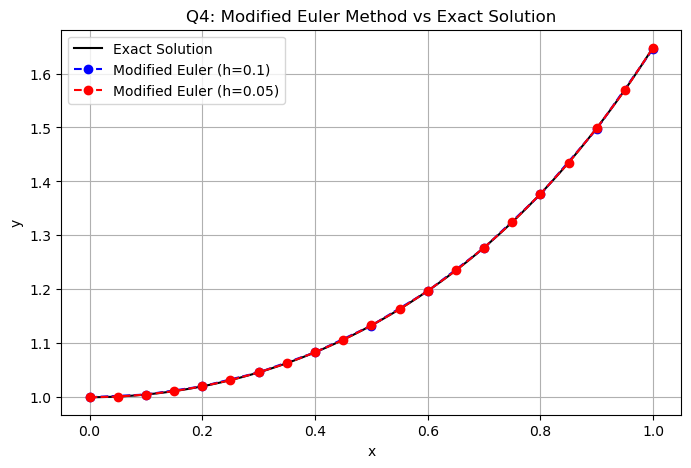

In [ ]:
# Q4

print_r, show_plt = save_op(4)


def modified_euler(f, x0, y0, x_end, h):
    n_steps = int(np.round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n_steps + 1)
    y = np.zeros(n_steps + 1)
    y[0] = y0
    for i in range(n_steps):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h/2, y[i] + (h/2) * k1)
        y[i+1] = y[i] + h * k2
    return x, y


f = lambda x, y: x * y
exact_f = lambda x: np.exp(x**2/2)

x_num1, y_num1 = modified_euler(f, 0, 1, 1, 0.1)
x_num2, y_num2 = modified_euler(f, 0, 1, 1, 0.05)

error1 = np.max(np.abs(y_num1 - exact_f(x_num1)))
error2 = np.max(np.abs(y_num2 - exact_f(x_num2)))
print_r("Maximum absolute errors at h = 0.1 and 0.05:", error1, error2)
print_r("Observed order =", np.log2(error1/error2))

x_exact = np.linspace(0, 1, 100)
y_exact = exact_f(x_exact)

plt.figure(figsize=(8, 5))
plt.plot(x_exact, y_exact, 'k-', label="Exact Solution")
plt.plot(x_num1, y_num1, 'bo--', label="Modified Euler (h=0.1)")
plt.plot(x_num2, y_num2, 'ro--', label="Modified Euler (h=0.05)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q4: Modified Euler Method vs Exact Solution")
plt.legend()
plt.grid(True)
show_plt()

Maximum absolute error = 4.814952048626253e-06


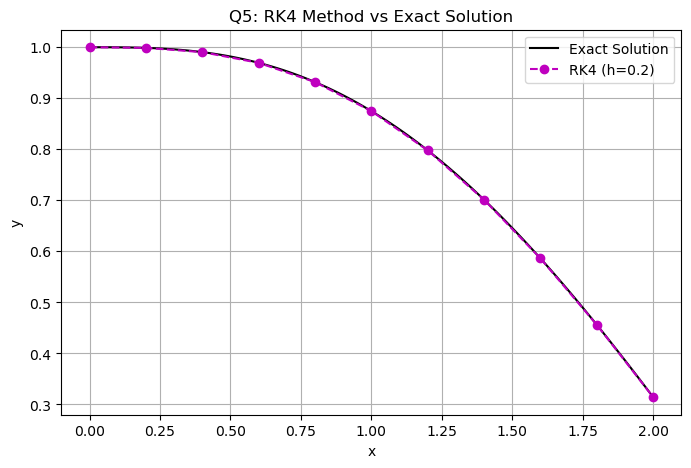

In [ ]:
# Q5

print_r, show_plt = save_op(5)


def rk4(f, x0, y0, x_end, h):
    n_steps = int(np.round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n_steps + 1)
    y = np.zeros(n_steps + 1)
    y[0] = y0
    for i in range(n_steps):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h/2, y[i] + h/2 * k1)
        k3 = f(x[i] + h/2, y[i] + h/2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i+1] = y[i] + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
    return x, y


f = lambda x, y: np.cos(x) - y
exact_f = lambda x: 0.5 * (np.sin(x) + np.cos(x)) + 0.5 * np.exp(-x)
x_num, y_num = rk4(f, 0, 1, 2, 0.2)

print_r("Maximum absolute error =", np.max(np.abs(y_num - exact_f(x_num))))

x_exact = np.linspace(0, 2, 100)
y_exact = exact_f(x_exact)

plt.figure(figsize=(8, 5))
plt.plot(x_exact, y_exact, 'k-', label="Exact Solution")
plt.plot(x_num, y_num, 'mo--', label="RK4 (h=0.2)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q5: RK4 Method vs Exact Solution")
plt.legend()
plt.grid(True)
show_plt()


h = 0.25
x_n    | Euler      | Back Euler | Imp Euler  | Mod Euler  | RK4       
0.000  | 0.500000   | 0.500000   | 0.500000   | 0.500000   | 0.500000  
0.250  | 0.562500   | 0.561553   | 0.562012   | 0.562256   | 0.562176  
0.500  | 0.624023   | 0.620427   | 0.622123   | 0.622593   | 0.622459  
0.750  | 0.682678   | 0.675249   | 0.678668   | 0.679319   | 0.679178  
1.000  | 0.736835   | 0.725083   | 0.730381   | 0.731154   | 0.731058  


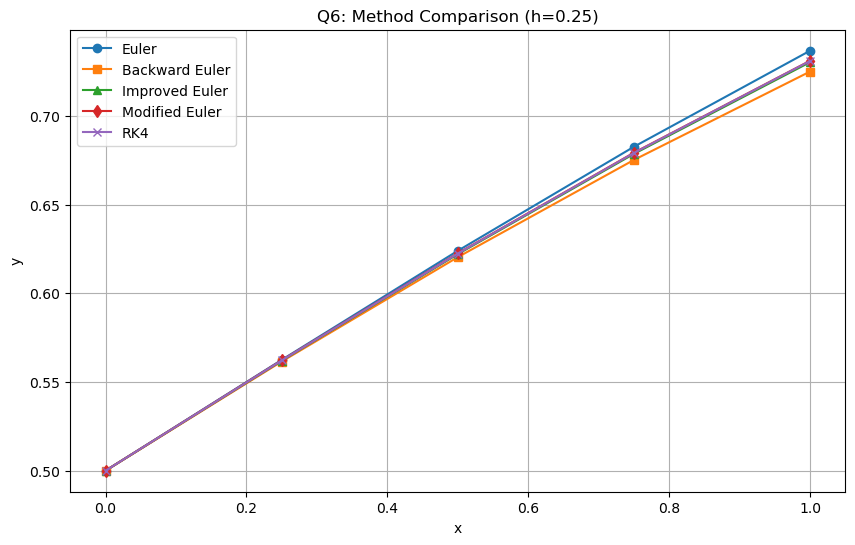


h = 0.125
x_n    | Euler      | Back Euler | Imp Euler  | Mod Euler  | RK4       
0.000  | 0.500000   | 0.500000   | 0.500000   | 0.500000   | 0.500000  
0.125  | 0.531250   | 0.531129   | 0.531189   | 0.531219   | 0.531209  
0.250  | 0.562378   | 0.561900   | 0.562135   | 0.562196   | 0.562176  
0.375  | 0.593142   | 0.592090   | 0.592605   | 0.592694   | 0.592667  
0.500  | 0.623307   | 0.621495   | 0.622377   | 0.622491   | 0.622459  
0.625  | 0.652657   | 0.649935   | 0.651251   | 0.651389   | 0.651355  
0.750  | 0.680994   | 0.677257   | 0.679054   | 0.679212   | 0.679179  
0.875  | 0.708149   | 0.703339   | 0.705641   | 0.705814   | 0.705785  
1.000  | 0.733983   | 0.728086   | 0.730895   | 0.731080   | 0.731059  


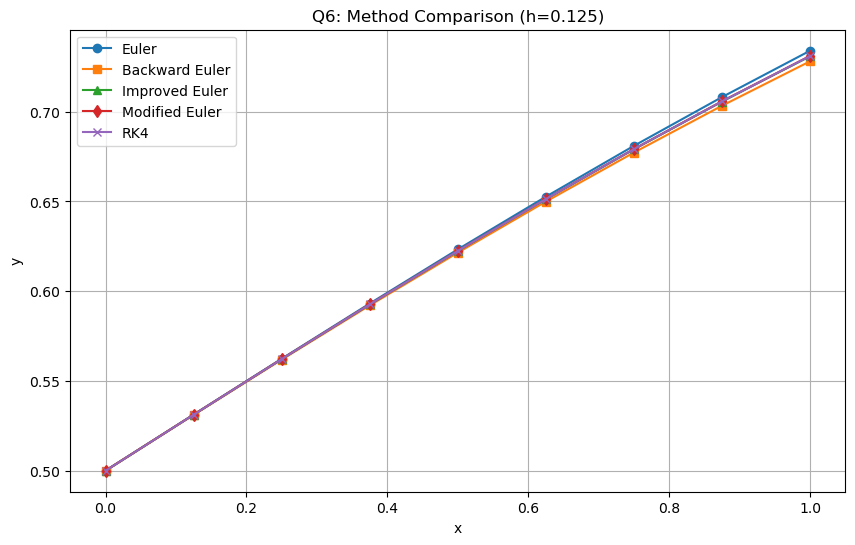

In [ ]:
# Q6
print_r, show_plt = save_op(6)

def backward_euler_q6(f, x0, y0, x_end, h):
    n_steps = int(np.round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n_steps + 1)
    y = np.zeros(n_steps + 1)
    y[0] = y0
    for i in range(n_steps):
        y_next = y[i] # Initial guess
        for _ in range(10): # 10 iterations max
            F = y_next - y[i] - h * y_next * (1 - y_next)
            dF = 1 - h * (1 - 2 * y_next)
            y_next = y_next - F/dF
        y[i+1] = y_next
    return x, y

f = lambda x, y: y * (1 - y)

for h in (0.25, 0.125):
    print_r(f"\nh = {h}")
    x_e, y_e = euler_method(f, 0, 0.5, 1, h)
    _, y_be = backward_euler_q6(f, 0, 0.5, 1, h)
    _, y_ie = improved_euler(f, 0, 0.5, 1, h)
    _, y_me = modified_euler(f, 0, 0.5, 1, h)
    _, y_rk = rk4(f, 0, 0.5, 1, h)

    print_r(f"{'x_n':<6} | {'Euler':<10} | {'Back Euler':<10} | {'Imp Euler':<10} | {'Mod Euler':<10} | {'RK4':<10}")
    for i in range(len(x_e)):
        print_r(f"{x_e[i]:<6.3f} | {y_e[i]:<10.6f} | {y_be[i]:<10.6f} | {y_ie[i]:<10.6f} | {y_me[i]:<10.6f} | {y_rk[i]:<10.6f}")

    plt.figure(figsize=(10, 6))
    plt.plot(x_e, y_e, 'o-', label="Euler")
    plt.plot(x_e, y_be, 's-', label="Backward Euler")
    plt.plot(x_e, y_ie, '^-', label="Improved Euler")
    plt.plot(x_e, y_me, 'd-', label="Modified Euler")
    plt.plot(x_e, y_rk, 'x-', label="RK4")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Q6: Method Comparison (h={h})")
    plt.legend()
    plt.grid(True)
    show_plt()